# 3. Matplotlib

## 3.1 Matplotlib and Its Core Concepts

Matplotlib is a data visualization library, and it can turn arrays from NumPy and dataframe in Pandas to pictures.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

x = np.array([1, 2, 3, 4, 5])
y = np.array([2, 4, 6, 8, 10])

plt.plot(x, y)
plt.show()

In Matplotlib, Figure is the whole canvas, Axes are cells of pictures inside it, and multiple lines can be draw in one Axes.


### 3.1.1 Figure - The Entire Canvas

Figure is the container of the whole picture, it may contain one or more axes, titles and shapes. For exaple:


In [ ]:
fig = plt.figure(
    figsize=(8, 5)
)  # figsize sets the hight and width of the canvas in inches.

### 3.1.2 Axes - The Plotting Area

A Figure can simultaneously contain a number of Axes, and it is a specific object type in Matplotlib. For a common 2D Plot, an Axes usually contains X axis and Y axis.

=> Figure contains Axes; Axes contains Axis objects and plotted data.


### 3.1.3 The Object-Oriented Interface

The `plt.plot()` used before belongs to the `pyplot` style. Matplotlib also offers a more advanced tool, that is the object-oriented interface.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

x = np.array([1, 2, 3, 4, 5])
y = 2 * x

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(x, y)

ax.set_title("Linear Relationship")
ax.set_xlabel("X Values")
ax.set_ylabel("Y Values")

plt.show()

Here, the `fig, ax = plt.subplots()` simultaneously creates:

- A Figure object which is assigned to fig;
- An Axes object which is assigned to ax;

Thus, we can use `ax.plot(x,y)` to draw figures on specified Axes.


### 3.1.4 Customizing a Plot

Matplotlib not only draw figures, but it can also adjust the visual expression of the plot. For example:


In [ ]:
x = np.array([1, 2, 3, 4, 5])
y = np.array([2, 4, 3, 7, 8])

fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(
    x,
    y,
    color="royalblue",
    linestyle="--",
    marker="o",
    linewidth=2,
    markersize=7,
    label="Model A",
)

ax.set_title("Model Performance")
ax.set_xlabel("Epoch")
ax.set_ylabel("Score")

ax.legend(loc="upper left")
ax.grid(True)

plt.show()

notice that `label` is used to define legend entry, while `legend()` is used to show the legend.


### 3.1.5 Scattered Plot & Line Plot

Sometimes we need the markers to be scattered for specific reasons. If so, we can use:


In [ ]:
ax.scatter(x, y)  # Scatter Plot
ax.plot(x, y)  # Line Plot

### 3.1.6 Subplots

A great advantage of object-oriented interface is that we can place multiple Axes in one Figure. For example:


In [ ]:
x = np.linspace(0, 10, 100)

fig, axes = plt.subplots(1, 2, figsize=(10, 2))

axes[0].plot(x, np.sin(x))
axes[0].set_title("Sine")

axes[1].plot(x, np.cos(x))
axes[1].set_title("Cosine")

plt.tight_layout()
plt.show()

Here, `plt.subplots(1,2)` sets the layout to one-row-two-column type. Thus, the `axes` it returns is an array that contains two Axes objects. We have to use `axes[0]` or `axes[1]` to visit each object.

However, when no layout manifesto is written, axes automatically turns to a Axes object, but not an array.


## 3.2 Scatter Plots & Bar Charts

### 3.2.1 Scatter Plot

Scatter plots are often used to show the correlation between the figures. For example:


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

study_hours = np.array([1, 2, 3, 4, 5, 6, 7, 8])
scores = np.array([45, 52, 58, 65, 72, 78, 85, 93])

fig, ax = plt.subplots(figsize=(7, 4))

ax.scatter(study_hours, scores)

ax.set_title("Study Hours vs Exam Scores")
ax.set_xlabel("Study Hours")
ax.set_ylabel("Exam Score")

plt.show()

Obviously, there is kind of positive relation between the study hours and scores. However, always understand that CORRELATION DOES NOT IMPLY CAUSATION. Furtheremore, there's some different about the parameters:

- In `ax.plot()`, we often use `markersize` to control the size of the marker, which is in diameter;
- In `ax.scatter()`, we often use `s` to control the size of the marker, which indicates marker area.


### 3.2.2 Scatter Plot for Classification

Boolean indexing can also be used in plots to indicate different kinds of data.


In [ ]:
X = np.array(
    [
        [1, 4],
        [2, 5],
        [3, 6],
        [4, 7],
    ]
)
y = np.array([0, 1, 0, 1])

print(X[y == 1, 0])

The code `X[y == 1, 0]` did two things:

1. Use the boolean condition `y == 1` to sort out the wanted rows;
2. Use the index figure `0` to choose the first element of each row.


In [ ]:
hours = np.array([1, 2, 3, 4, 5, 6, 7, 8])
scores = np.array([45, 52, 58, 65, 72, 78, 85, 93])
labels = np.array([0, 0, 0, 0, 1, 1, 1, 1])

fig, ax = plt.subplots(figsize=(7, 4))

ax.scatter(
    hours[labels == 0],
    scores[labels == 0],
    color="red",
    label="Failed",
)

ax.scatter(
    hours[labels == 1],
    scores[labels == 1],
    color="green",
    label="Passed",
)

ax.set_xlabel("Study Hours")
ax.set_ylabel("Exam Score")
ax.legend()

plt.show()

there's also an alternative, called 'One-Scatter-Call', which only calls the function once to complete the plot:


In [ ]:
fig, ax = plt.subplots()

scatter = ax.scatter(
    hours,
    scores,
    c=labels,  # cast the label array onto the color of markers
    cmap="coolwarm",
)

plt.show()

### 3.2.3 Bar Chart

Different from scatter plot, bar chart is mainly used to compare values among multiple categories. For example:


In [ ]:
subjects = ["Math", "English", "Python", "Physics"]
averages = [82, 88, 91, 79]

fig, ax = plt.subplots(figsize=(7, 4))

ax.bar(subjects, averages)

ax.set_title("Average Scores by Subject")
ax.set_xlabel("Subject")
ax.set_ylabel("Average Score")

plt.show()

Besides `.bar()`, `.barh()` plots a horizontal bar chart, which put the categories on the y-axis.


### 3.2.4 Grouped Bar Chart

If we want to put more than one group of data onto the same bar chart, but only do the plotting twice, the chart will overlap. Thus, we have to explicitly set the bar position.


In [ ]:
subjects = ["Math", "English", "Python"]
class_a = np.array([85, 90, 88])
class_b = np.array([80, 86, 92])

x = np.arange(
    len(subjects)
)  # equivalent to x = np.array([0,1,2]), which sets the x-axis. This is because two bars cannot be auto formed.
width = 0.35

fig, ax = plt.subplots(figsize=(8, 4))

ax.bar(
    x - width / 2,
    class_a,
    width=width,
    label="Class A",
)
ax.bar(
    x + width / 2,
    class_b,
    width=width,
    label="Class B",
)

ax.set_xticks(x, subjects)
ax.set_ylabel("Average Score")
ax.set_title("Class Comparison")
ax.legend()

plt.show()

## 3.3 More Chart Types

### 3.3.1 Histogram

Histogram is somewhat similar to bar chart. However, its x-axis is conducted by value intervals (bins), and its y-axis is the fraction frequency/count. It is mainly used statistically for distribution.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

scores = np.array(
    [52, 58, 63, 65, 67, 70, 72, 73, 75, 76, 78, 80, 81, 82, 84, 85, 88, 90, 93, 96]
)

fig, ax = plt.subplots(figsize=(7, 4))

ax.hist(
    scores,
    bins=[50, 60, 70, 80, 90, 100],
    color="steelblue",
    edgecolor="black",
    # density=True
)

ax.set_title("Exam Score Distribution")
ax.set_xlabel("Score")
ax.set_ylabel("Frequency")

plt.show()

in the code above:

- `bins` determines how to break the numerical data into intervals, and is set as [x, y) by default;
- `density` decides whether to normalize to a probability density.


### 3.3.2 Box Plots

Box plots ar widely used to percive the center of numerical data and probable outliers.

#### 3.3.2.1 Preparation

Before we dive into it, we should first know:

1. Minimum;
2. First Quartile (Q1)
3. Median (Q2)
4. Third Quartile (Q3)
5. Maximum

However, the box plots whiskers do not always extends to the minimum and the maximum.

#### 3.3.2.2 Interquartile Range (IQR)

Basically, IQR is the deduction of Q3 and Q1:

$$
IQR = Q3 - Q1
$$

Matplotlib uses `whis=1.5` as default, which means that the whisker extends to:

$$
[Q1 - 1.5IQR,\ Q3 + 1/5IQR]
$$

Samples outside this interval will be marked as outliers outside the box.


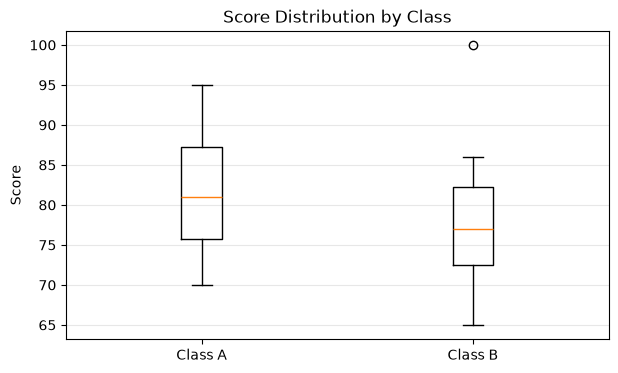

In [6]:
class_a = [70, 72, 75, 78, 80, 82, 85, 88, 91, 95]
class_b = [65, 69, 72, 74, 76, 78, 80, 83, 86, 100]

fig, ax = plt.subplots(figsize=(7, 4))

ax.boxplot(
    [class_a, class_b],
    tick_labels=["Class A", "Class B"],
)

ax.set_title("Score Distribution by Class")
ax.set_ylabel("Score")
ax.grid(axis="y", alpha=0.3)

plt.show()

### 3.3.3 Pie Charts

Pie chart is mainly used to show proportions. For example:


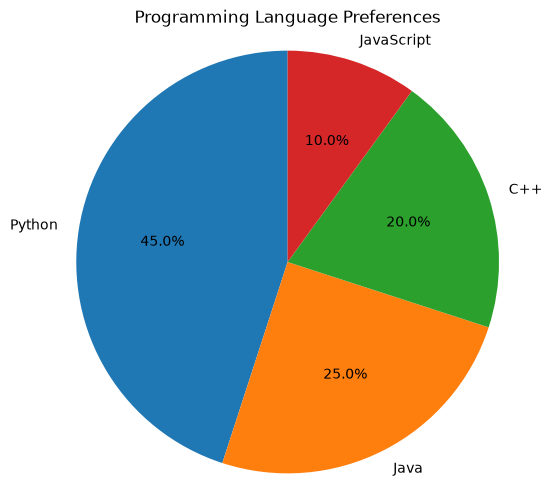

In [9]:
languages = ["Python", "Java", "C++", "JavaScript"]
counts = [45, 25, 20, 10]

fig, ax = plt.subplots(figsize=(6, 6))

ax.pie(
    counts,
    labels=languages,
    autopct="%.1f%%",  # print style formatting, `%1f` means one decimal place, and `%%` outputs the percentage sign.
    startangle=90,  # starts at 90 degrees, and goes counter-clockwise by default. To go clockwise, use `counterclock=False`
    # counterclock=False
)

ax.set_title("Programming Language Preferences")
ax.axis("equal")

plt.show()

## 3.4 Three Dimentional Scatter Plot

### 3.4.1 Creating a 3D Axes

Compared to traditional 2D data, we have to explicitly appoint the Axes when defining:


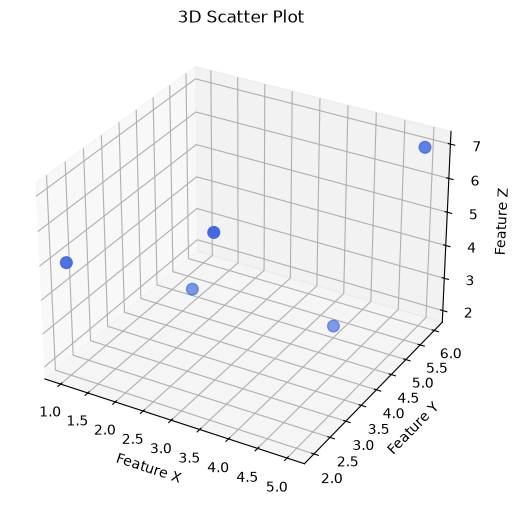

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

x = np.array([1, 2, 3, 4, 5])
y = np.array([2, 4, 3, 5, 6])
z = np.array([5, 3, 6, 2, 7])

fig, ax = plt.subplots(
    figsize=(7, 6),
    subplot_kw={
        "projection": "3d"
    },  # keyword argument `projection` is set to "3d" to create a 3D plot.
)

ax.scatter(x, y, z, color="royalblue", s=70)

ax.set_title("3D Scatter Plot")
ax.set_xlabel("Feature X")
ax.set_ylabel("Feature Y")
ax.set_zlabel("Feature Z")

plt.show()

A step more from above, we can combine boolean indexing to realize classification:


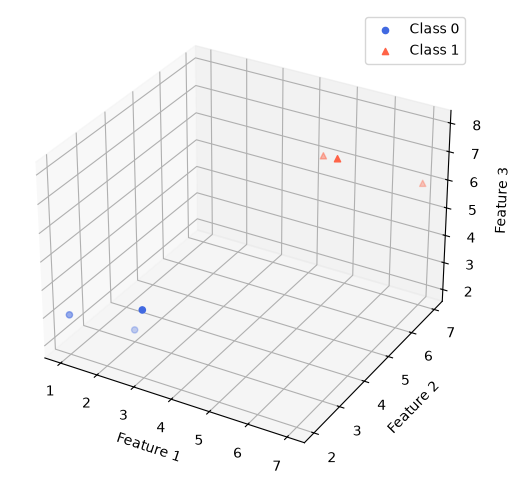

In [11]:
X = np.array(
    [
        [1, 2, 3],
        [2, 3, 2],
        [3, 2, 4],
        [5, 6, 7],
        [6, 5, 8],
        [7, 7, 6],
    ]
)
y = np.array([0, 0, 0, 1, 1, 1])

fig, ax = plt.subplots(
    figsize=(7, 6),
    subplot_kw={"projection": "3d"},
)

ax.scatter(
    X[y == 0, 0],
    X[y == 0, 1],
    X[y == 0, 2],
    color="royalblue",
    marker="o",
    label="Class 0",
)
ax.scatter(
    X[y == 1, 0],
    X[y == 1, 1],
    X[y == 1, 2],
    color="tomato",
    marker="^",
    label="Class 1",
)

ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
ax.set_zlabel("Feature 3")
ax.legend()

plt.show()

We can also add things to adjust the view point of 3D scatter plots, for example:


In [ ]:
ax.view_init(elev=25, azim=45)

in which:

- `elev` is the elevation angle;
- `azim` is the azimuth angle that surrounds the z-axis.
